🦄 PROJECT EVERETT: Quantum Molecular Docking Engine 🦄

Training QML Model on 160 molecular samples...
Epoch 010/100 | Quantum Loss (MSE): 0.92137
Epoch 020/100 | Quantum Loss (MSE): 0.89100
Epoch 030/100 | Quantum Loss (MSE): 0.88068
Epoch 040/100 | Quantum Loss (MSE): 0.87281
Epoch 050/100 | Quantum Loss (MSE): 0.86877
Epoch 060/100 | Quantum Loss (MSE): 0.86684
Epoch 070/100 | Quantum Loss (MSE): 0.86634
Epoch 080/100 | Quantum Loss (MSE): 0.86621
Epoch 090/100 | Quantum Loss (MSE): 0.86614
Epoch 100/100 | Quantum Loss (MSE): 0.86610

Evaluating Model on Test Set...
Test Loss (MSE): 1.13742


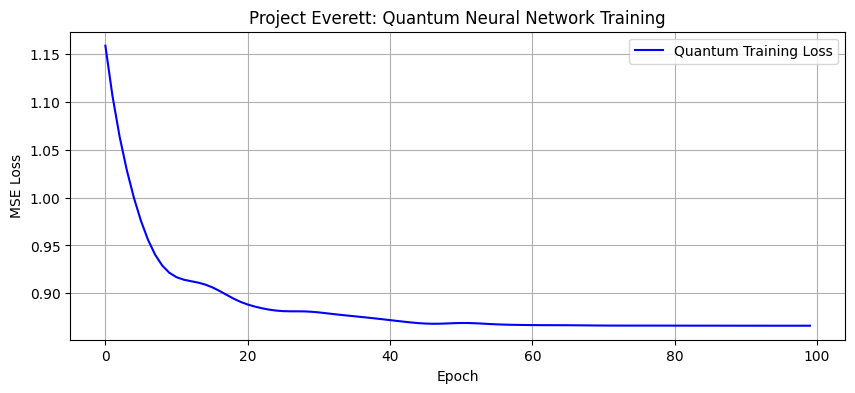

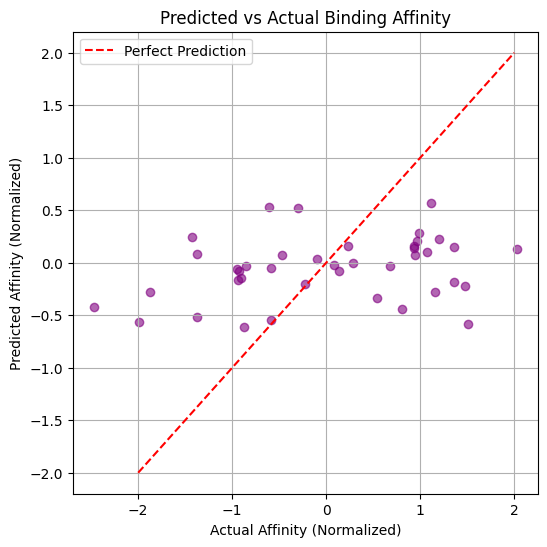


✅ Execution Complete. Model ready for GitHub push.


In [2]:
# ==============================================================================
# PROJECT EVERETT - Quantum-Enhanced Molecular Binding Affinity Predictor
# Author: Katchaw451
# Framework: PennyLane + PyTorch
# Description: This script uses a Variational Quantum Circuit (VQC) to predict
#              the binding affinity of drug-like molecules. The quantum circuit
#              leverages superposition to explore multiple states simultaneously.
# ==============================================================================

# 1. INSTALL DEPENDENCIES
!pip install pennylane torch matplotlib pandas scikit-learn -q

import pennylane as qml
from pennylane import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

print("======================================================")
print("🦄 PROJECT EVERETT: Quantum Molecular Docking Engine 🦄")
print("======================================================\n")

# 2. DATA PREPARATION (Synthetic Dataset for PoC)
# We simulate 4 classical molecular descriptors: MW, LogP, TPSA, H-Bond Donors.
# The target is the Binding Affinity (Delta G in kcal/mol) - a continuous value.
num_samples = 200
num_features = 4

# Generate synthetic molecular data
X_raw = np.random.rand(num_samples, num_features) * 10
# Generate a non-linear synthetic target (simulating complex quantum interactions)
y_raw = np.sin(X_raw[:, 0]) + np.cos(X_raw[:, 1]) * 0.5 - X_raw[:, 2] * 0.1 + np.random.normal(0, 0.1, num_samples)

# Normalize data for the quantum circuit (Angle Embedding requires values between -pi/2 and pi/2)
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X_raw)
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y_raw.reshape(-1, 1))

# Convert to PyTorch tensors
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
y_tensor = torch.tensor(y_scaled, dtype=torch.float32)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

# 3. QUANTUM CIRCUIT DEFINITION (PennyLane)
n_qubits = num_features
n_layers = 2 # Number of entanglement layers

# Use a standard simulator
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    # A) State Preparation: Encode classical molecular features into quantum states
    # This puts the qubits into a superposition of states.
    qml.AngleEmbedding(features=inputs, wires=range(n_qubits), rotation='Y')

    # B) Variational Layers: Explore multiple quantum states simultaneously
    # StronglyEntanglingLayers applies rotations and CNOT gates to create entanglement
    qml.StronglyEntanglingLayers(weights=weights, wires=range(n_qubits))

    # C) Measurement: Return the expectation value of the first qubit
    return qml.expval(qml.PauliZ(0))

# Define the shape of the quantum weights: (Layers, Qubits, 3 rotation angles)
weight_shapes = {"weights": (n_layers, n_qubits, 3)}

# 4. HYBRID CLASSICAL-QUANTUM NEURAL NETWORK (FIXED)
class QuantumDockingModel(nn.Module):
    def __init__(self):
        super(QuantumDockingModel, self).__init__()
        # Quantum Layer
        self.qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        # Classical Layer to scale the quantum output to our target range
        self.classical_layer = nn.Linear(1, 1)

    def forward(self, x):
        x = self.qlayer(x)
        # FIX: Reshape the 1D tensor (160,) to 2D (160, 1)
        x = x.reshape(-1, 1)
        x = self.classical_layer(x)
        return x

model = QuantumDockingModel()

# 5. TRAINING THE MODEL
epochs = 100
learning_rate = 0.05
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

loss_history = []

print(f"Training QML Model on {len(X_train)} molecular samples...")
for epoch in range(epochs):
    optimizer.zero_grad()

    # Forward pass
    predictions = model(X_train)
    loss = loss_fn(predictions, y_train)

    # Backward pass (Quantum gradients via parameter-shift rule)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:03d}/{epochs} | Quantum Loss (MSE): {loss.item():.5f}")

# 6. EVALUATION & VISUALIZATION
print("\nEvaluating Model on Test Set...")
model.eval()
with torch.no_grad():
    test_predictions = model(X_test)
    test_loss = loss_fn(test_predictions, y_test)
    print(f"Test Loss (MSE): {test_loss.item():.5f}")

# Plot Training Loss
plt.figure(figsize=(10, 4))
plt.plot(loss_history, color='blue', label='Quantum Training Loss')
plt.title('Project Everett: Quantum Neural Network Training')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot Predictions vs Reality
plt.figure(figsize=(6, 6))
plt.scatter(y_test.numpy(), test_predictions.numpy(), alpha=0.6, color='purple')
plt.plot([-2, 2], [-2, 2], 'r--', label='Perfect Prediction')
plt.title('Predicted vs Actual Binding Affinity')
plt.xlabel('Actual Affinity (Normalized)')
plt.ylabel('Predicted Affinity (Normalized)')
plt.legend()
plt.grid(True)
plt.show()

print("\n======================================================")
print("✅ Execution Complete. Model ready for GitHub push.")
print("======================================================")